In [4]:
#Numpy and Datascience modules
import numpy as np
from datascience import *

import matplotlib
%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')
import warnings
warnings.simplefilter('ignore', FutureWarning)

In [5]:
builiding = "T," * 81 + "O," * 135
#get rid of the empty string element
labels = builiding.split(",")[:216]

#BPMs of songs in a spotify playlist called TurboFolk Serbia + songs mentioned in the Sources I've read
turbofolkBPM = make_array(115, 100, 124, 96, 136, 93, 128, 196, 137, 140, 112, 142, 137, 180, 137, 120, 130, 113, 141, 150, 141, 138, 176, 112, 158, 115, 130, 94, 118, 134, 168, 115, 130, 160, 148, 156, 130, 100, 124, 144, 180, 121, 134, 110, 138, 120, 145, 102, 152, 152, 120, 140, 151, 127, 137, 128, 156, 110, 136, 156, 146, 170, 122, 130, 100, 120, 128, 198, 156, 156, 144, 142, 120, 150, 174, 196, 172, 140, 98, 135, 117)  
#BPM of a mix of other song genres (Narodna (roughly translates to national music) Rock n Roll, Folklore, Svedalinka, Folk)  
otherBPM = make_array(98, 123, 104, 123, 91, 112, 128, 148, 204, 113, 112, 120, 140, 76, 107, 203, 108, 135, 138, 111, 147, 144, 135, 128, 123, 108, 160, 167, 106, 149, 130, 104, 146, 125, 133, 88, 139, 83, 154, 127, 147, 106, 115, 107, 151, 143, 128, 115, 162, 123, 169, 115, 120, 160, 110, 129, 137, 151, 140, 82, 124, 130, 106, 174, 99, 104, 152, 131, 113, 138, 186, 131, 125, 114, 96, 135, 123, 125, 120, 173, 153, 168, 96, 134, 109, 164, 167, 129, 174, 78, 178, 124, 136, 121, 113, 95, 112, 131, 114, 130, 128, 130, 88, 98, 92, 119, 126, 84, 118, 97, 111, 67, 138, 131, 108, 130, 92, 144, 89, 95, 148, 208, 162, 153, 95, 97, 65, 104, 106, 65, 110, 68, 111, 92, 102)

BPM = np.append(turbofolkBPM,otherBPM) #for the table
#observed values
TFavg = np.mean(turbofolkBPM) 
Oavg = np.mean(otherBPM) 

songs = Table()
songs = songs.with_columns("Label", labels , "BPM", BPM)

observed = TFavg - Oavg
(TFavg, Oavg, observed)

(136.38271604938271, 124.41481481481482, 11.96790123456789)

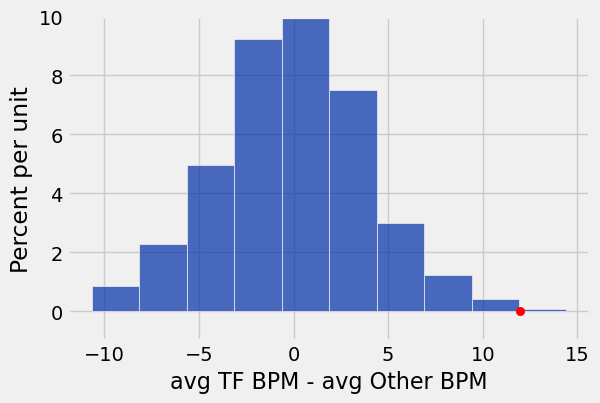

In [6]:
#Bootstrapping from our sample
differences = make_array()
for i in np.arange(1000):
    bootstrap = songs.with_columns("NewLabel", songs.sample(with_replacement=False).column("Label"))
    newTFavg = np.average(bootstrap.where("NewLabel", "T").column("BPM"))
    newOavg = np.average(bootstrap.where("NewLabel", "O").column("BPM"))
    difference = newTFavg - newOavg
    differences = np.append(differences, difference)
# compare our observed difference to that of the differences under the null hypothesis (that average BPM of turbofolk does not differ to that of other genres) 
Table().with_column("avg TF BPM - avg Other BPM", differences).hist("avg TF BPM - avg Other BPM")
plots.scatter(observed, 0, color='red')
plots.ylim(-0.01,0.1);

In [7]:
p = np.count_nonzero(observed <= differences) / len(differences)
p
#null can be regect with p cutoff of 1%

0.002

In [9]:
#Turb0Folk
TFmedian = np.median(turbofolkBPM)
TFQ1 = np.percentile(turbofolkBPM, 25)
TFQ3 = np.percentile(turbofolkBPM, 75)
TFIQR = TFQ3-TFQ1
(min(turbofolkBPM), TFQ1, TFmedian, TFQ3, max(turbofolkBPM), TFIQR)

(93, 120.0, 136.0, 150.0, 198, 30.0)

In [10]:
#other
nozero = otherBPM[:135]
Omedian = np.median(otherBPM)
OQ1 = np.percentile(otherBPM, 25)
OQ3 = np.percentile(otherBPM, 75)
OIQR = OQ3-OQ1
(min(nozero), OQ1, Omedian, OQ3, max(nozero), OIQR)

(65, 106.0, 123.0, 139.5, 208, 33.5)